In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)


In [5]:
file_path = r"C:\Users\yigit\Documents\Customer-Uplift-Retention-Simulator\data\raw\Online Retail.xlsx"

df = pd.read_excel(file_path)
df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [9]:
df.describe()


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [11]:
df.isnull().sum()


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [13]:
df['CustomerID'].nunique()


4372

In [15]:

df[df['Quantity'] < 0].shape, df[df['UnitPrice'] <= 0].shape


((10624, 8), (2517, 8))

In [17]:
df[df['Quantity'] < 0].head(10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [19]:
df['CustomerID'].isna().mean(), df['CustomerID'].isna().sum()


(0.249266943342886, 135080)

In [21]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df = df.sort_values('InvoiceDate')
df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [23]:
n_rows = len(df)
n_customers = df['CustomerID'].nunique()
n_invoices = df['InvoiceNo'].nunique()
total_revenue = df['TotalPrice'].sum()

n_rows, n_customers, n_invoices, total_revenue


(541909, 4372, 25900, 9747747.934000002)

In [25]:
daily_revenue = (
    df.groupby(df['InvoiceDate'].dt.date)['TotalPrice']
      .sum()
      .reset_index(name='Revenue')
)

daily_revenue.head()


,InvoiceDate,Revenue
0,2010-12-01,58635.56
1,2010-12-02,46207.28
2,2010-12-03,45620.46
3,2010-12-05,31383.95
4,2010-12-06,53860.18


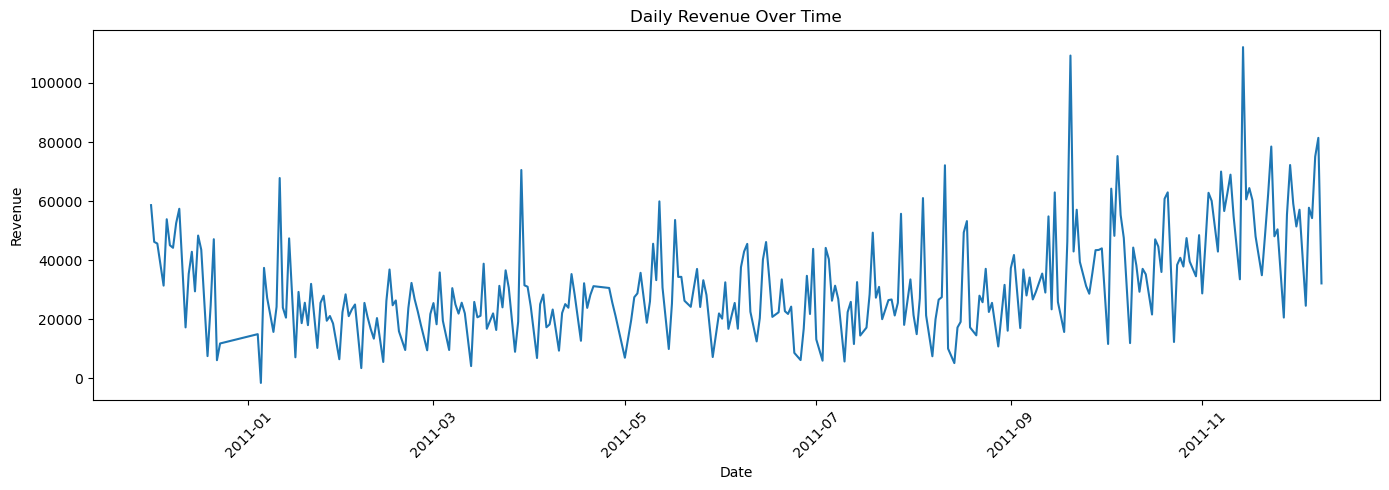

In [27]:
plt.figure(figsize=(14,5))
plt.plot(daily_revenue['InvoiceDate'], daily_revenue['Revenue'])
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.title('Daily Revenue Over Time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [29]:
country_revenue = (
    df.groupby('Country')['TotalPrice']
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

country_revenue.head(10)


,Country,TotalPrice
0,United Kingdom,8187806.364
1,Netherlands,284661.540
2,EIRE,263276.820
3,Germany,221698.210
4,France,197403.900
5,Australia,137077.270
6,Switzerland,56385.350
7,Spain,54774.580
8,Belgium,40910.960
9,Sweden,36595.910


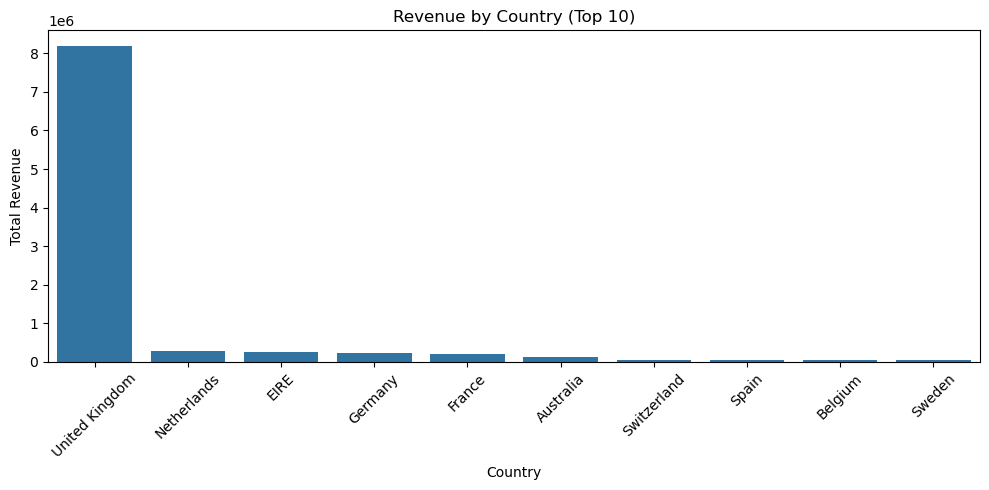

In [31]:
top_countries = country_revenue.head(10)

plt.figure(figsize=(10,5))
sns.barplot(data=top_countries, x='Country', y='TotalPrice')
plt.xticks(rotation=45)
plt.title('Revenue by Country (Top 10)')
plt.ylabel('Total Revenue')
plt.tight_layout()
plt.show()


In [33]:
customer_revenue = (
    df.groupby('CustomerID')['TotalPrice']
      .sum()
      .reset_index(name='CustomerRevenue')
)

customer_revenue.describe()


,CustomerID,CustomerRevenue
count,4372.000000,4372.000000
mean,15299.677722,1898.459701
std,1722.390705,8219.345141
min,12346.000000,-4287.630000
25%,13812.750000,293.362500
50%,15300.500000,648.075000
75%,16778.250000,1611.725000
max,18287.000000,279489.020000


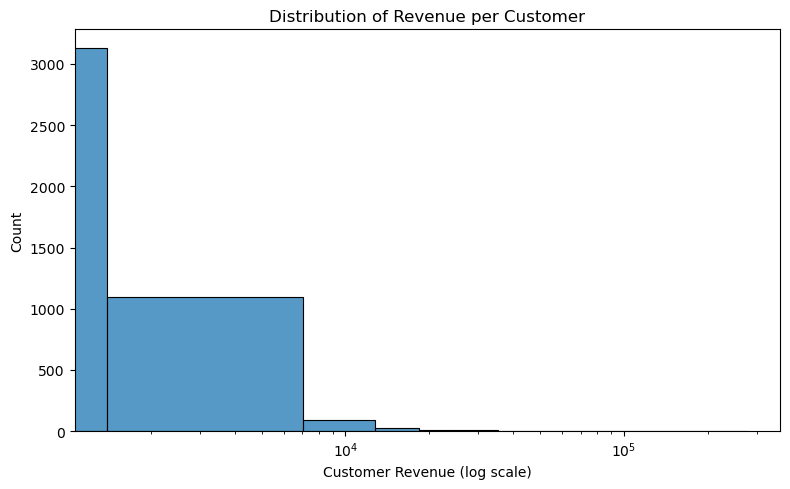

In [35]:
plt.figure(figsize=(8,5))
sns.histplot(customer_revenue['CustomerRevenue'], bins=50)
plt.xscale('log')
plt.xlabel('Customer Revenue (log scale)')
plt.title('Distribution of Revenue per Customer')
plt.tight_layout()
plt.show()


In [37]:
orders_per_customer = (
    df.groupby('CustomerID')['InvoiceNo']
      .nunique()
      .reset_index(name='OrderCount')
)

orders_per_customer.describe()


,CustomerID,OrderCount
count,4372.000000,4372.000000
mean,15299.677722,5.075480
std,1722.390705,9.338754
min,12346.000000,1.000000
25%,13812.750000,1.000000
50%,15300.500000,3.000000
75%,16778.250000,5.000000
max,18287.000000,248.000000


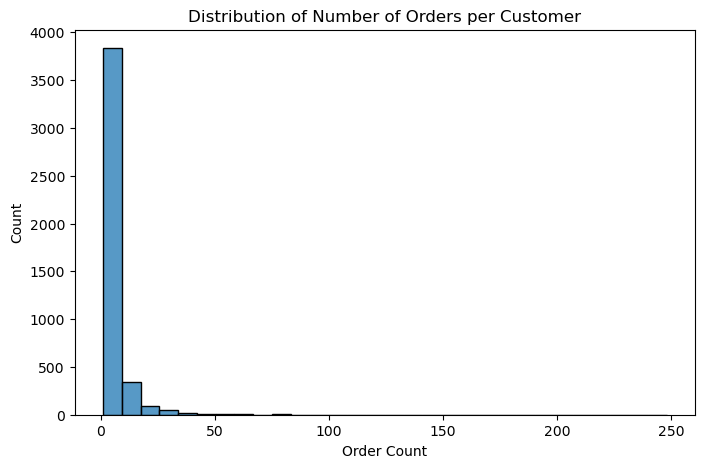

In [39]:
plt.figure(figsize=(8,5))
sns.histplot(orders_per_customer['OrderCount'], bins=30)
plt.title("Distribution of Number of Orders per Customer")
plt.xlabel("Order Count")
plt.ylabel("Count")
plt.show()


In [41]:
one_time_customers = (orders_per_customer['OrderCount'] == 1).sum()
repeat_customers = (orders_per_customer['OrderCount'] > 1).sum()

one_time_customers, repeat_customers


(1313, 3059)

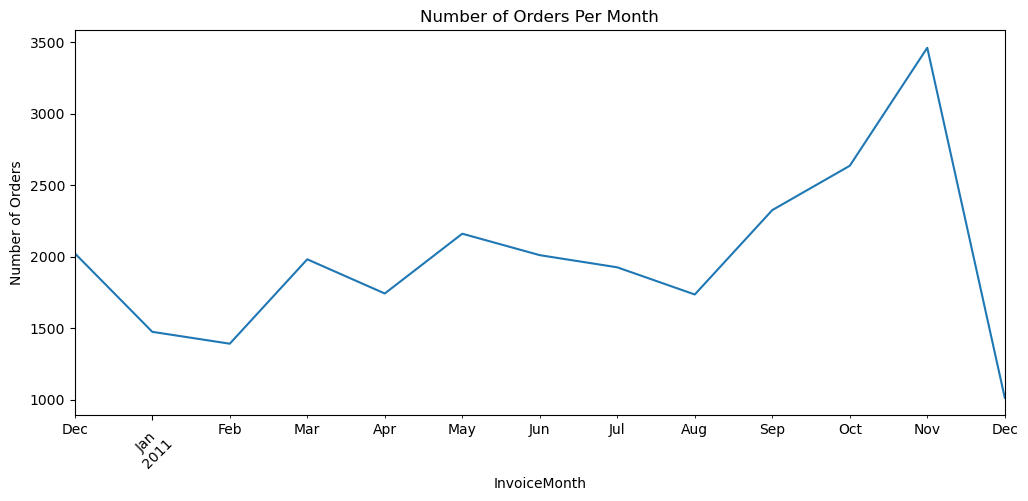

In [43]:
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')

monthly_orders = df.groupby('InvoiceMonth')['InvoiceNo'].nunique()

plt.figure(figsize=(12,5))
monthly_orders.plot()
plt.title("Number of Orders Per Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()


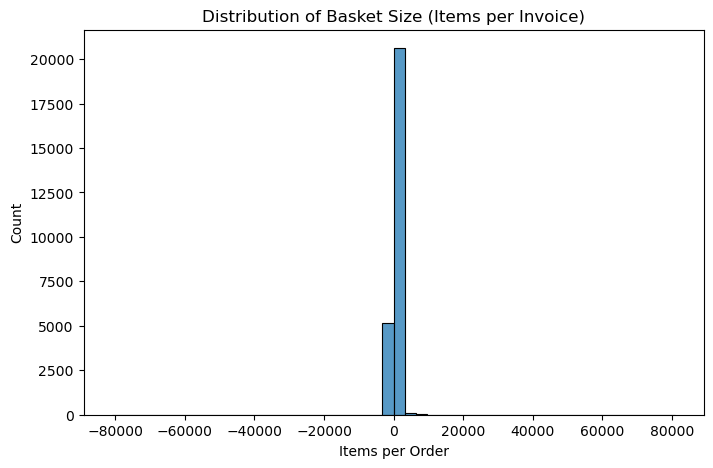

In [45]:
basket_size = df.groupby('InvoiceNo')['Quantity'].sum()

plt.figure(figsize=(8,5))
sns.histplot(basket_size, bins=50)
plt.title("Distribution of Basket Size (Items per Invoice)")
plt.xlabel("Items per Order")
plt.ylabel("Count")
plt.show()


In [47]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']


In [49]:
df = df[df['CustomerID'].notnull()]


In [51]:
df = df[df['Quantity'] > 0]


In [53]:
df = df[df['TotalPrice'] > 0]


In [55]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])


In [57]:
df = df.sort_values('InvoiceDate')


In [59]:
df.info(), df.describe()


<class 'pandas.core.frame.DataFrame'>
Index: 397884 entries, 0 to 541908
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   InvoiceNo     397884 non-null  object        
 1   StockCode     397884 non-null  object        
 2   Description   397884 non-null  object        
 3   Quantity      397884 non-null  int64         
 4   InvoiceDate   397884 non-null  datetime64[ns]
 5   UnitPrice     397884 non-null  float64       
 6   CustomerID    397884 non-null  float64       
 7   Country       397884 non-null  object        
 8   TotalPrice    397884 non-null  float64       
 9   InvoiceMonth  397884 non-null  period[M]     
dtypes: datetime64[ns](1), float64(3), int64(1), object(4), period[M](1)
memory usage: 33.4+ MB


(None,
             Quantity                    InvoiceDate      UnitPrice  \
 count  397884.000000                         397884  397884.000000   
 mean       12.988238  2011-07-10 23:41:23.511023360       3.116488   
 min         1.000000            2010-12-01 08:26:00       0.001000   
 25%         2.000000            2011-04-07 11:12:00       1.250000   
 50%         6.000000            2011-07-31 14:39:00       1.950000   
 75%        12.000000            2011-10-20 14:33:00       3.750000   
 max     80995.000000            2011-12-09 12:50:00    8142.750000   
 std       179.331775                            NaN      22.097877   
 
           CustomerID     TotalPrice  
 count  397884.000000  397884.000000  
 mean    15294.423453      22.397000  
 min     12346.000000       0.001000  
 25%     13969.000000       4.680000  
 50%     15159.000000      11.800000  
 75%     16795.000000      19.800000  
 max     18287.000000  168469.600000  
 std      1713.141560     309.071041  )

In [63]:
import datetime as dt

snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)
snapshot_date


Timestamp('2011-12-10 12:50:00')

In [65]:
rfm = (
    df.groupby('CustomerID')
    .agg({
        'InvoiceDate': lambda x: (snapshot_date - x.max()).days,  # Recency
        'InvoiceNo': 'nunique',                                   # Frequency
        'TotalPrice': 'sum'                                       # Monetary
    })
    .rename(columns={
        'InvoiceDate': 'Recency',
        'InvoiceNo': 'Frequency',
        'TotalPrice': 'Monetary'
    })
)

rfm.head()


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [67]:
rfm.describe()


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


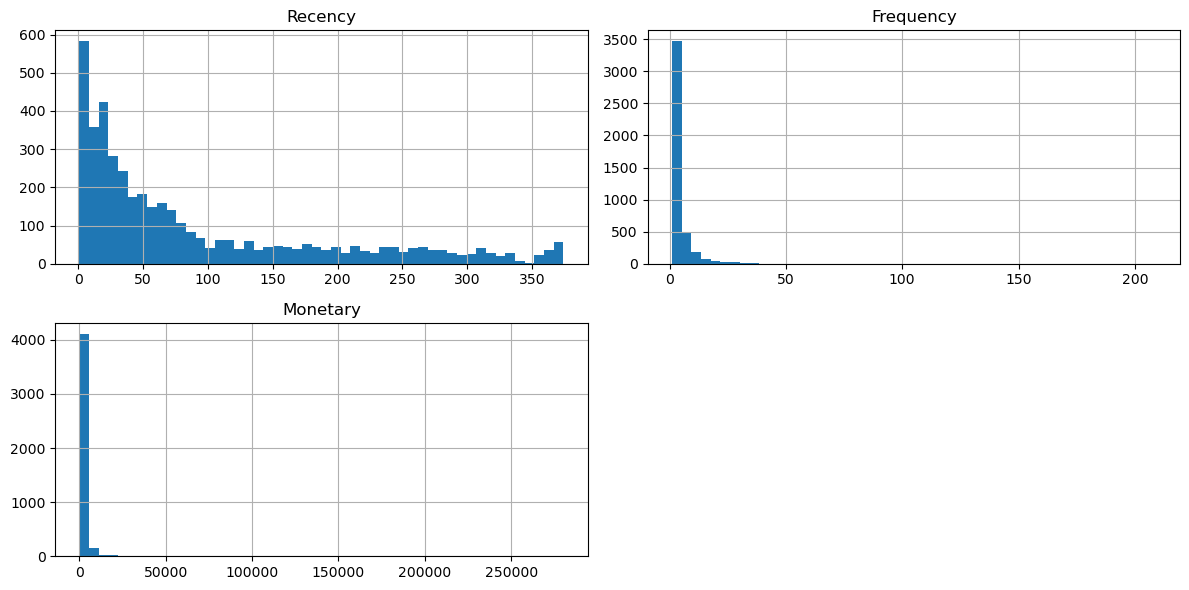

In [69]:
rfm.hist(figsize=(12,6), bins=50)
plt.tight_layout()
plt.show()


In [71]:
rfm.to_csv("C:/Users/yigit/Documents/Customer-Uplift-Retention-Simulator/data/processed/rfm.csv")


In [73]:
last_date = df['InvoiceDate'].max()
last_date


Timestamp('2011-12-09 12:50:00')

In [75]:
customer_last_purchase = (
    df.groupby('CustomerID')['InvoiceDate']
      .max()
      .reset_index(name='LastPurchaseDate')
)

customer_last_purchase['DaysSinceLastPurchase'] = \
    (last_date - customer_last_purchase['LastPurchaseDate']).dt.days


In [77]:
rfm = rfm.merge(customer_last_purchase[['CustomerID', 'DaysSinceLastPurchase']],
                on='CustomerID',
                how='left')


In [79]:
rfm['Churn'] = (rfm['DaysSinceLastPurchase'] > 90).astype(int)


In [81]:
rfm[['Recency','Frequency','Monetary','DaysSinceLastPurchase','Churn']].head()


,Recency,Frequency,Monetary,DaysSinceLastPurchase,Churn
0,326,1,77183.60,325,1
1,2,7,4310.00,1,0
2,75,4,1797.24,74,0
3,19,1,1757.55,18,0
4,310,1,334.40,309,1


In [83]:
rfm.to_csv("C:/Users/yigit/Documents/Customer-Uplift-Retention-Simulator/data/processed/rfm_churn.csv", index=False)


In [85]:
rfm_churn = pd.read_csv("C:/Users/yigit/Documents/Customer-Uplift-Retention-Simulator/data/processed/rfm_churn.csv")
rfm_churn.head()


,CustomerID,Recency,Frequency,Monetary,DaysSinceLastPurchase,Churn
0,12346.0,326,1,77183.60,325,1
1,12347.0,2,7,4310.00,1,0
2,12348.0,75,4,1797.24,74,0
3,12349.0,19,1,1757.55,18,0
4,12350.0,310,1,334.40,309,1


In [95]:
from sklearn.model_selection import train_test_split

X = rfm_churn[['Frequency', 'Monetary']]
y = rfm_churn['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train.shape, X_test.shape


((3470, 2), (868, 2))

In [97]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)


RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

In [99]:
from sklearn.metrics import classification_report, roc_auc_score

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:,1]

print(classification_report(y_test, y_pred))
print("AUC:", roc_auc_score(y_test, y_proba))


              precision    recall  f1-score   support

           0       0.71      0.73      0.72       579
           1       0.43      0.40      0.42       289

    accuracy                           0.62       868
   macro avg       0.57      0.57      0.57       868
weighted avg       0.62      0.62      0.62       868

AUC: 0.64997818694683


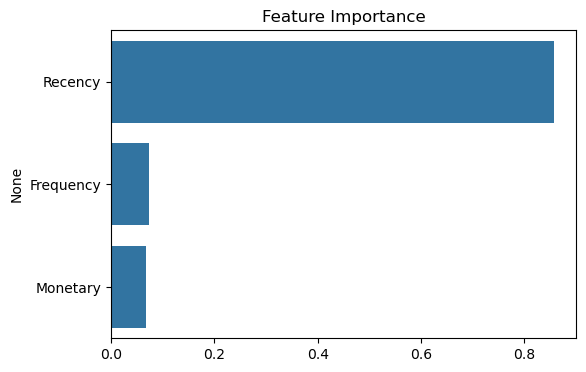

In [93]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.barplot(x=model.feature_importances_, y=X.columns)
plt.title("Feature Importance")
plt.show()


In [101]:
from sklearn.ensemble import GradientBoostingClassifier


In [103]:
gb_model = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)


GradientBoostingClassifier(learning_rate=0.05, n_estimators=300,
                           random_state=42)

In [105]:
y_pred_gb = gb_model.predict(X_test)
y_proba_gb = gb_model.predict_proba(X_test)[:, 1]

print("Gradient Boosting Classifier:")
print(classification_report(y_test, y_pred_gb))
print("AUC:", roc_auc_score(y_test, y_proba_gb))


Gradient Boosting Classifier:
              precision    recall  f1-score   support

           0       0.75      0.81      0.78       579
           1       0.54      0.45      0.49       289

    accuracy                           0.69       868
   macro avg       0.64      0.63      0.63       868
weighted avg       0.68      0.69      0.68       868

AUC: 0.7519467402931912


In [107]:
!pip install xgboost


In [109]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score


In [111]:
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    random_state=42,
    eval_metric="logloss"   # avoids warning
)

xgb_model.fit(X_train, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=None, num_parallel_tree=None, random_state=42, ...)

In [113]:
y_pred_xgb = xgb_model.predict(X_test)
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost Classifier:")
print(classification_report(y_test, y_pred_xgb))

auc_xgb = roc_auc_score(y_test, y_proba_xgb)
acc_xgb = accuracy_score(y_test, y_pred_xgb)

print("AUC:", auc_xgb)
print("Accuracy:", acc_xgb)


XGBoost Classifier:
              precision    recall  f1-score   support

           0       0.76      0.81      0.79       579
           1       0.57      0.49      0.52       289

    accuracy                           0.71       868
   macro avg       0.66      0.65      0.66       868
weighted avg       0.70      0.71      0.70       868

AUC: 0.756733659632704
Accuracy: 0.7050691244239631


In [125]:

rfm_churn['Churn_Prob'] = xgb_model.predict_proba(
    rfm_churn[['Frequency','Monetary']]
)[:, 1]

rfm_churn['Risk'] = pd.cut(
    rfm_churn['Churn_Prob'],
    bins=[0, 0.3, 0.6, 1.0],
    labels=['Low', 'Medium', 'High']
)


rfm_churn['Treatment'] = 0
rfm_churn.loc[rfm_churn['Risk']=='High', 'Treatment'] = 1
rfm_churn.loc[rfm_churn['Risk']=='Medium', 'Treatment'] = np.random.binomial(1, 0.3, size=(rfm_churn['Risk']=='Medium').sum())

def simulate_response(row):
    if row['Treatment'] == 1:
        if row['Risk'] == 'High':
            return np.random.binomial(1, 0.40)
        elif row['Risk'] == 'Medium':
            return np.random.binomial(1, 0.20)
        else:
            return np.random.binomial(1, 0.05)
    else: # control
        return np.random.binomial(1, 0.03)

rfm_churn['Response'] = rfm_churn.apply(simulate_response, axis=1)

treatment_rate = rfm_churn[rfm_churn['Treatment']==1]['Response'].mean()
control_rate = rfm_churn[rfm_churn['Treatment']==0]['Response'].mean()
uplift = treatment_rate - control_rate

print("Treatment Retention Rate:", treatment_rate)
print("Control Retention Rate:", control_rate)
print("Uplift:", uplift)


Treatment Retention Rate: 0.3102189781021898
Control Retention Rate: 0.03146206045650833
Uplift: 0.27875691764568145


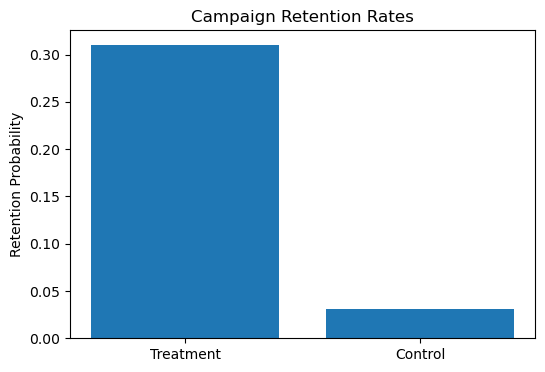

In [127]:
plt.figure(figsize=(6,4))
plt.bar(['Treatment','Control'], [treatment_rate, control_rate])
plt.title("Campaign Retention Rates")
plt.ylabel("Retention Probability")
plt.show()


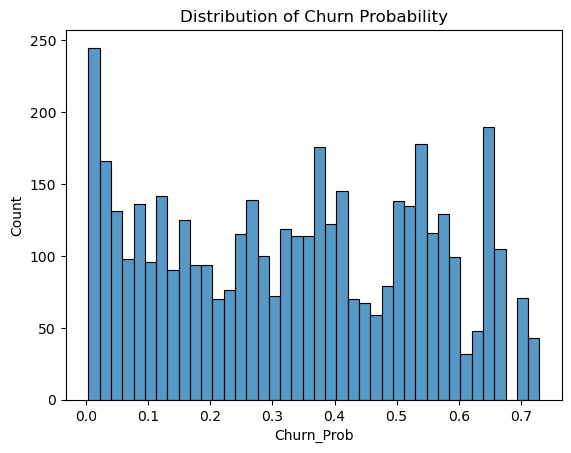

In [129]:
sns.histplot(rfm_churn['Churn_Prob'], bins=40)
plt.title("Distribution of Churn Probability")
plt.show()


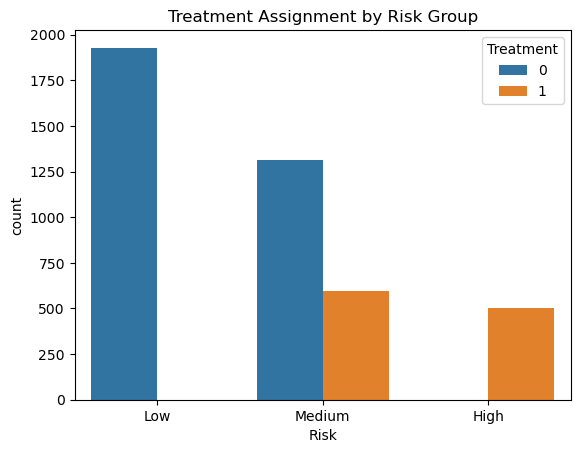

In [131]:
sns.countplot(data=rfm_churn, x='Risk', hue='Treatment')
plt.title("Treatment Assignment by Risk Group")
plt.show()


In [133]:

df_uplift = rfm_churn.dropna(subset=['Response']).copy()

feature_cols = ['Recency', 'Frequency', 'Monetary', 'Churn_Prob', 'Risk']

X = pd.get_dummies(df_uplift[feature_cols], drop_first=True)

treatment = df_uplift['Treatment']  # 1 = got offer, 0 = control
y = df_uplift['Response']           # 1 = stayed / converted, 0 = churned

X.shape, treatment.shape, y.shape


((4338, 6), (4338,), (4338,))

In [135]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier

X_train, X_test, t_train, t_test, y_train, y_test = train_test_split(
    X, treatment, y,
    test_size=0.2,
    random_state=42,
    stratify=treatment  
)


X_train_treat = X_train[t_train == 1]
y_train_treat = y_train[t_train == 1]

X_train_ctrl = X_train[t_train == 0]
y_train_ctrl = y_train[t_train == 0]


gb_treat = GradientBoostingClassifier(random_state=42)
gb_ctrl  = GradientBoostingClassifier(random_state=42)

gb_treat.fit(X_train_treat, y_train_treat)
gb_ctrl.fit(X_train_ctrl, y_train_ctrl)


GradientBoostingClassifier(random_state=42)

In [137]:
from sklearn.metrics import roc_auc_score

p_treat = gb_treat.predict_proba(X_test)[:, 1]
p_ctrl  = gb_ctrl.predict_proba(X_test)[:, 1]

uplift_scores = p_treat - p_ctrl

uplift_df = pd.DataFrame({
    'uplift': uplift_scores,
    'treatment': t_test.values,
    'response': y_test.values
})

uplift_df.head()


,uplift,treatment,response
0,0.016956,0,0
1,0.543806,0,0
2,0.534269,1,1
3,0.138740,1,0
4,0.397677,0,0


In [139]:

uplift_df['bucket'] = pd.qcut(uplift_df['uplift'], q=5, labels=False, duplicates='drop')

def bucket_stats(g):
    treat_rate = g.loc[g['treatment'] == 1, 'response'].mean()
    ctrl_rate  = g.loc[g['treatment'] == 0, 'response'].mean()
    return pd.Series({
        'treatment_rate': treat_rate,
        'control_rate': ctrl_rate,
        'uplift': treat_rate - ctrl_rate,
        'count': len(g)
    })

bucket_results = uplift_df.groupby('bucket').apply(bucket_stats)


bucket_results.sort_index(ascending=False)


C:\Users\yigit\AppData\Local\Temp\ipykernel_19136\1834685725.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bucket_results = uplift_df.groupby('bucket').apply(bucket_stats)


,treatment_rate,control_rate,uplift,count
bucket,,,,
4,0.445946,0.010000,0.435946,174.0
3,0.310345,0.026087,0.284258,173.0
2,0.216216,0.022222,0.193994,172.0
1,0.416667,0.035971,0.380695,175.0
0,0.142857,0.037500,0.105357,174.0


In [143]:
rfm_churn.columns


Index(['CustomerID', 'Recency', 'Frequency', 'Monetary',
       'DaysSinceLastPurchase', 'Churn', 'Churn_Prob', 'Treatment', 'Response',
       'Risk'],
      dtype='object')

In [145]:
from sklearn.model_selection import train_test_split

feature_cols = ['Recency', 'Frequency', 'Monetary', 'Churn_Prob']

X = rfm_churn[feature_cols]
t = rfm_churn['Treatment']   # 1 = got offer, 0 = control
y = rfm_churn['Response']    # 1 = stayed / responded, 0 = churned


In [147]:
from sklearn.ensemble import GradientBoostingClassifier

gb_treat = GradientBoostingClassifier(
    learning_rate=0.05,
    n_estimators=300,
    max_depth=3,
    random_state=42
)

gb_ctrl = GradientBoostingClassifier(
    learning_rate=0.05,
    n_estimators=300,
    max_depth=3,
    random_state=42
)


gb_treat.fit(X_train[t_train == 1], y_train[t_train == 1])


gb_ctrl.fit(X_train[t_train == 0], y_train[t_train == 0])


GradientBoostingClassifier(learning_rate=0.05, n_estimators=300,
                           random_state=42)

In [149]:
p_treat_test = gb_treat.predict_proba(X_test)[:, 1]
p_ctrl_test  = gb_ctrl.predict_proba(X_test)[:, 1]

uplift_test = p_treat_test - p_ctrl_test

uplift_test[:10]

array([-0.01856478,  0.47153915,  0.55412099,  0.1228169 ,  0.25305778,
        0.10195261,  0.31273484,  0.13580288,  0.36617642,  0.13587216])

In [151]:

gb_treat_full = GradientBoostingClassifier(
    learning_rate=0.05,
    n_estimators=300,
    max_depth=3,
    random_state=42
)

gb_ctrl_full = GradientBoostingClassifier(
    learning_rate=0.05,
    n_estimators=300,
    max_depth=3,
    random_state=42
)

gb_treat_full.fit(X[t == 1], y[t == 1])
gb_ctrl_full.fit(X[t == 0], y[t == 0])

p_treat_all = gb_treat_full.predict_proba(X)[:, 1]
p_ctrl_all  = gb_ctrl_full.predict_proba(X)[:, 1]


rfm_churn['Uplift_Score'] = p_treat_all - p_ctrl_all

rfm_churn[['CustomerID', 'Recency', 'Frequency', 'Monetary',
           'Churn_Prob', 'Treatment', 'Response', 'Uplift_Score']].head()


,CustomerID,Recency,Frequency,Monetary,Churn_Prob,Treatment,Response,Uplift_Score
0,12346.0,326,1,77183.60,0.363132,1,0,-0.331399
1,12347.0,2,7,4310.00,0.024672,0,0,-0.032957
2,12348.0,75,4,1797.24,0.125767,0,0,0.581327
3,12349.0,19,1,1757.55,0.318127,0,0,0.104637
4,12350.0,310,1,334.40,0.547563,0,0,0.174070


In [153]:
rfm_churn_sorted = rfm_churn.sort_values(by='Uplift_Score', ascending=False)
rfm_churn_sorted[['CustomerID', 'Uplift_Score']].head(10)


,CustomerID,Uplift_Score
3764,17504.0,0.907918
441,12916.0,0.897642
3932,17723.0,0.885041
241,12643.0,0.885041
1124,13869.0,0.877543
277,12686.0,0.868469
2076,15180.0,0.862631
3448,17050.0,0.862293
953,13631.0,0.856078
2307,15491.0,0.856009


In [155]:
top_20pct_cutoff = rfm_churn['Uplift_Score'].quantile(0.8)
target_customers = rfm_churn[rfm_churn['Uplift_Score'] >= top_20pct_cutoff]

target_customers.head()


,CustomerID,Recency,Frequency,Monetary,DaysSinceLastPurchase,Churn,Churn_Prob,Treatment,Response,Risk,Uplift_Score
2,12348.0,75,4,1797.24,74,0,0.125767,0,0,Low,0.581327
6,12353.0,204,1,89.00,203,1,0.724031,1,1,High,0.655481
16,12363.0,110,2,552.00,109,1,0.396799,0,0,Medium,0.328191
22,12372.0,72,3,1298.04,71,0,0.228674,0,0,Low,0.351174
31,12383.0,185,5,1850.56,184,1,0.071169,0,0,Low,0.752101


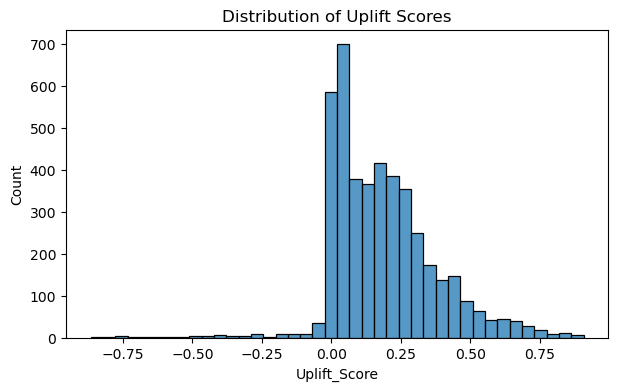

In [157]:
plt.figure(figsize=(7,4))
sns.histplot(rfm_churn['Uplift_Score'], bins=40)
plt.title("Distribution of Uplift Scores")
plt.show()


In [159]:
print("Total Customers:", len(rfm_churn))
print("Target Customers:", len(target_customers))
print("Average Uplift (all):", rfm_churn['Uplift_Score'].mean())
print("Average Uplift (target):", target_customers['Uplift_Score'].mean())


Total Customers: 4338
Target Customers: 868
Average Uplift (all): 0.18587096508698386
Average Uplift (target): 0.47188363701820146


In [161]:
top_20pct_cutoff = rfm_churn['Uplift_Score'].quantile(0.8)
target_customers = rfm_churn[rfm_churn['Uplift_Score'] >= top_20pct_cutoff]


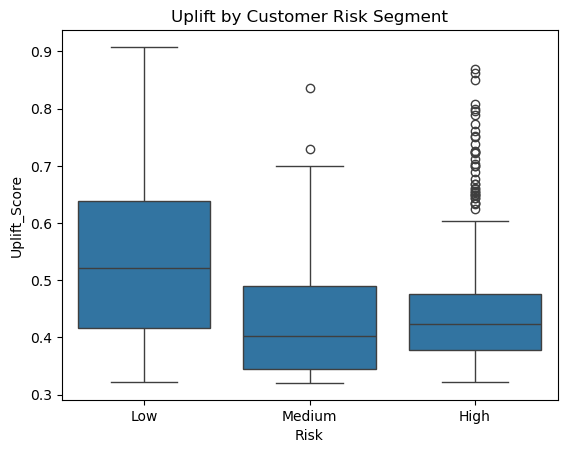

In [163]:
sns.boxplot(data=target_customers, x='Risk', y='Uplift_Score')
plt.title("Uplift by Customer Risk Segment")
plt.show()


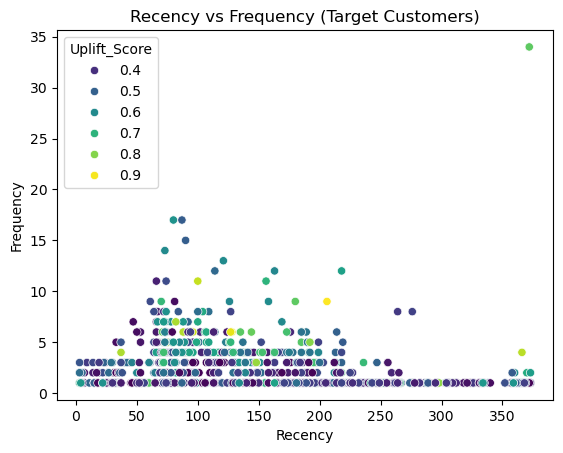

In [165]:
sns.scatterplot(data=target_customers, x='Recency', y='Frequency',
                hue='Uplift_Score', palette='viridis')
plt.title("Recency vs Frequency (Target Customers)")
plt.show()


In [167]:
target_customers[['CustomerID','Uplift_Score']].to_csv("Final_Target_Customers.csv", index=False)


In [169]:
rfm_churn.to_csv("Final_Uplift_Model_Dataset.csv", index=False)
